# Accessing the MEDICANES atlas

The MEDICANES atlas contains observations from different satellites over medicane events in Mediterranean Sea. All data are available at Ifremer : https://data-cersat.ifremer.fr/data/storms/medicanes/storm-atlas/

In particular, the `climatology` folder contains observations from various satellite products colocated with Mediterranean storms, from 1991 to 2020. The storms are numbered from 513 (example: `track00000513`) to 1716 (`track00001716`). Each storm folder contains subfolders, for each observation product that was colocated with the storm trajectory. For instance for storm folder `track00001556`, the `SCATSAT1-L2-ICM` subfolder contains wind speed and direction by Indian scatterometer SCATSAT-1. The different passes of this satellite colocated with this storm are stored in time ordered subfolders (<year/day in the year>, for instance `track00001556/SCATSAT1-L2-ICM/2017/040/` 

All storm trajectories are stored in the file (in parquet format): https://data-cersat.ifremer.fr/data/storms/medicanes/tracks/climatology/medicanes_cl7.parquet 

## Collecting data from the Atlas

Let's collect for instance an observation file from SCATSAT-1 scatterometer for the storm `track00001556`:

In [1]:
import urllib.request
urllib.request.urlretrieve('https://data-cersat.ifremer.fr/data/storms/medicanes/storm-atlas/climatology/track00001586/SCATSAT1-L2-ICM/2018/033/20180202182824_track00001586_SCATSAT1-L2-ICM.nc', "20180202182824_track00001586_SCATSAT1-L2-ICM.nc")

('20180202182824_track00001586_SCATSAT1-L2-ICM.nc',
 <http.client.HTTPMessage at 0x7026502de490>)

## Read and display

The file downloaded above is in satellite projection (swath along the satellite track). We can display its content easily:

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER
import xarray as xr

First open the file and display its content:

In [3]:
ds = xr.open_dataset('20180202182824_track00001586_SCATSAT1-L2-ICM.nc')
ds

<xarray.Dataset> Size: 315kB
Dimensions:           (row: 81, cell: 81)
Coordinates:
    time              (row, cell) datetime64[ns] 52kB ...
    lat               (row, cell) float32 26kB ...
    lon               (row, cell) float32 26kB ...
Dimensions without coordinates: row, cell
Data variables:
    model_speed       (row, cell) float32 26kB ...
    model_dir         (row, cell) float32 26kB ...
    ice_prob          (row, cell) float32 26kB ...
    ice_age           (row, cell) float32 26kB ...
    wvc_quality_flag  (row, cell) float64 52kB ...
    wind_speed        (row, cell) float32 26kB ...
    wind_dir          (row, cell) float32 26kB ...
Attributes: (12/81)
    title:                                      ScatSat-1 OSCAT Level 2 25.0 ...
    title_short_name:                           OSCAT-L2-25km
    Conventions:                                CF-1.4
    institution:                                EUMETSAT/OSI SAF/KNMI
    source:                                     ScatSat-1 OSCAT
    software_identification_level_1:            2202
    ...                                         ...
    publisher_email:                            cersat@ifremer.fr
    processing_software:                        Cersat/Cerbere 1.0
    geospatial_lat_units:                       degrees
    geospatial_lon_units:                       degrees
    geospatial_vertical_units:                  meters above mean sea level
    geospatial_vertical_positive:               up

Let's display the wind speed measured by the scatterometer:

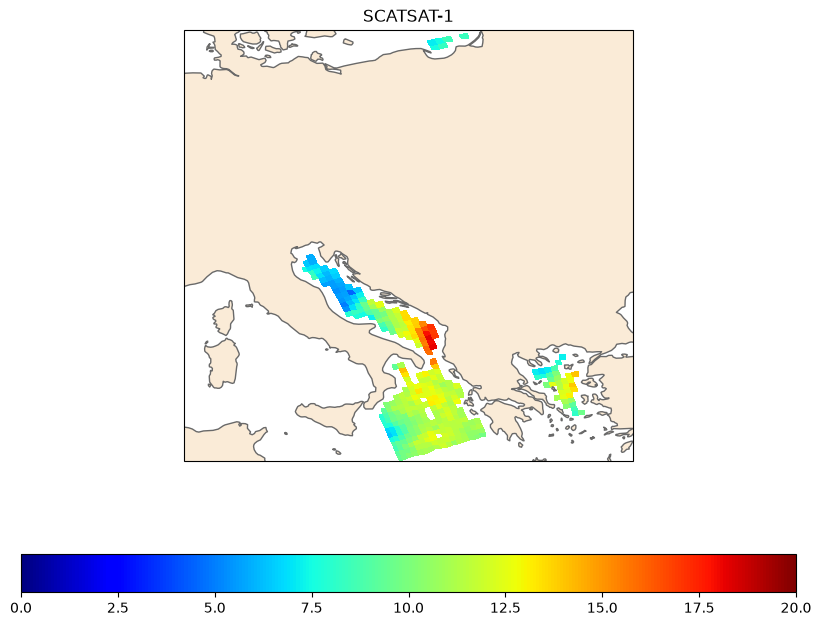

In [6]:
# 1. Initialize the figure and map projection
fig = plt.figure(figsize=(10, 8))
ax = plt.axes(projection=ccrs.PlateCarree())

# 2. Add base map layers and features
ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='antiquewhite')
ax.add_feature(cfeature.COASTLINE, edgecolor='dimgray', linewidth=1)

# 3. Display the wind speed variable
# ignore the invalid lat/lon when plotting
valid = np.isfinite(ds.lon)
cax = ax.pcolormesh(ds.lon.where(valid, drop=True), ds.lat.where(valid, drop=True), ds.wind_speed.where(valid, drop=True), vmin=0,vmax=20, cmap='jet')

## Uncomment for gridlines
# 4. Configure gridlines and coordinate labels
# gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
#                   linewidth=0.5, color='gray', alpha=0.5, linestyle='--')

# Disable labels on the top and right side for a cleaner layout
# gl.top_labels = False
# gl.right_labels = False

# Format labels to show degrees East/West and North/South
# gl.xformatter = LONGITUDE_FORMATTER
# gl.yformatter = LATITUDE_FORMATTER

plt.colorbar(cax, orientation='horizontal')

plt.title("SCATSAT-1")

# Save or display the map
plt.show()